<a href="https://colab.research.google.com/github/nickkraus52/MachineLearning/blob/main/HW5/diabetes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Load the dataset into a Pandas DataFrame.

For this assignment I downloaded the dataset as a csv and imported it using read_csv, assigning the proper column names. I then printed the head function to make sure the dataset was properly imported.

In [2]:
import pandas as pd
import numpy as np

cols = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
        "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Target"]
df = pd.read_csv("pima-indians-diabetes.csv", header=None, names=cols)

print('First 5 Elements:')
display(df.head())

First 5 Elements:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Target
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Inspecting the Dataset

I ran the info function on the Dataframe to see the columns and their datatypes. I recognized that all the columns were numerical data types, so no categorical values. I also ran the describe and value_counts functions to double check for categorical features and the data distribution.

In [3]:
print('Column Names and Data Types:')
display(df.info())

print('\nData Statistical Distribution: ')
display(df.describe().T)

Column Names and Data Types:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Target                    768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


None


Data Statistical Distribution: 


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Target,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
for col in cols:
    print(f'\n{col} Distribution:')
    display(df[col].value_counts())


Pregnancies Distribution:


,count
Pregnancies,
1,135
0,111
2,103
3,75
4,68
5,57
6,50
7,45
8,38



Glucose Distribution:


,count
Glucose,
99,17
100,17
111,14
125,14
129,14
...,...
56,1
169,1
149,1



BloodPressure Distribution:


...

,count
DiabetesPedigreeFunction,
0.258,6
0.254,6
0.207,5
0.261,5
0.259,5
...,...
0.565,1
0.118,1
0.177,1



Age Distribution:


,count
Age,
22,72
21,63
25,48
24,46
23,38
28,35
26,33
27,32
29,29



Target Distribution:


,count
Target,
0,500
1,268


## Imputing Missing or Implicit Values
The method I used to import the dataset had every column imported as a numerical type without nulls included. Instead implicit missing values are stored as 0s in features that can't possibly be 0. I then replaced all the 0s to np.nan so these values could be easily imputed. Then I created a simple imputer with a median strategy.

In [5]:
print('Values with 0: ')
display((df == 0).sum())

print('\nNull Values: ')
display(df.isnull().sum())

Values with 0: 


,0
Pregnancies,111
Glucose,5
BloodPressure,35
SkinThickness,227
Insulin,374
BMI,11
DiabetesPedigreeFunction,0
Age,0
Target,500



Null Values: 


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Target,0


In [6]:
from sklearn.impute import SimpleImputer
from sklearn.base import clone

df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']] = df[['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']].replace(0, np.nan)

imputer = SimpleImputer(strategy='median')

sample_df = pd.DataFrame(imputer.fit_transform(df), columns=df.columns)

print('\nNull Values: ')
display(sample_df.isnull().sum())

print('\nData Statistical Distribution: ')
display(sample_df.describe().T)



Null Values: 


,0
Pregnancies,0
Glucose,0
BloodPressure,0
SkinThickness,0
Insulin,0
BMI,0
DiabetesPedigreeFunction,0
Age,0
Target,0



Data Statistical Distribution: 


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,121.656250,30.438286,44.000,99.75000,117.0000,140.25000,199.00
BloodPressure,768.0,72.386719,12.096642,24.000,64.00000,72.0000,80.00000,122.00
SkinThickness,768.0,29.108073,8.791221,7.000,25.00000,29.0000,32.00000,99.00
Insulin,768.0,140.671875,86.383060,14.000,121.50000,125.0000,127.25000,846.00
BMI,768.0,32.455208,6.875177,18.200,27.50000,32.3000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Target,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


## Building a Pipeline with Encoding and Scaling

First I import the modules to create the pipeline. I combine them into a single column transformer. I used the simple imputer with median strategy and a standard scaler for the numerical pipeline. There was no categorical features so I just made the numerical pipeline and added it to the preprocessing Column Transformer.

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

X = df.drop(columns=['Target'])
y = df['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

num_pipeline = Pipeline([
    ('imputer', imputer),
    ('scaler', StandardScaler())
])

preprocessor = ColumnTransformer([
    ('pipe', num_pipeline, X.columns)
])

display(preprocessor)

ColumnTransformer(transformers=[('pipe',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 Index(['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin',
       'BMI', 'DiabetesPedigreeFunction', 'Age'],
      dtype='object'))])

## Training Models Hard Vs. Soft Classifiers (SVC/DT/LogisticRegression)

I first import all the modules needed to created the hard and soft ensamble models. I then set up the estimators for these ensamble as SVM, Decision Tree, and Logistic Regression. I fitted each model and ran classification reports for them. Finally I added the results for each model to a Data Frame to show the results of each model. The Data Frame showed that the Soft Voting operated the best for this data set and test split.

In [8]:
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier, BaggingClassifier, AdaBoostClassifier
from matplotlib import pyplot as plt

estimators = [
    ('SVM', SVC(probability=True, kernel='rbf', random_state=42)),
    ('DecisionTree', DecisionTreeClassifier(max_depth=5, random_state=42)),
    ('LogisticRegression', LogisticRegression(max_iter=1000, random_state=42))
]

hard_voting = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('voting', VotingClassifier(estimators=estimators, voting='hard'))
])

soft_voting = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('voting', VotingClassifier(estimators=estimators, voting='soft'))
])

models = {}

for name, model in estimators:
    pipeline = Pipeline([
        ('preprocessor', clone(preprocessor)),
        ('classifier', model)
    ]).fit(X_train, y_train)

    report = classification_report(y_test, pipeline.predict(X_test), target_names=['No Diabetes', 'Diabetes'], output_dict=True)
    models[name] = {
        'Accuracy': report['accuracy'],
        'Precision': report['Diabetes']['precision'],
        'Recall': report['Diabetes']['recall'],
        'F1 Score': report['Diabetes']['f1-score']
    }

soft_pred = soft_voting.fit(X_train, y_train).predict(X_test)
hard_pred = hard_voting.fit(X_train, y_train).predict(X_test)

for name, pred in [('Soft Voting', soft_pred), ('Hard Voting', hard_pred)]:
    report = classification_report(y_test, pred, target_names=['No Diabetes', 'Diabetes'], output_dict=True)
    models[name] = {
        'Accuracy': report['accuracy'],
        'Precision': report['Diabetes']['precision'],
        'Recall': report['Diabetes']['recall'],
        'F1 Score': report['Diabetes']['f1-score']
    }

pd.DataFrame(models).sort_values(by='Accuracy', axis=1, ascending=False).T

,Accuracy,Precision,Recall,F1 Score
Soft Voting,0.772727,0.692308,0.654545,0.672897
Hard Voting,0.759740,0.673077,0.636364,0.654206
LogisticRegression,0.753247,0.666667,0.618182,0.641509
SVM,0.746753,0.666667,0.581818,0.621359
DecisionTree,0.727273,0.591549,0.763636,0.666667


## Training a Bagging Classifier

First I created a bagging model using the preprocessor I made before. I created it with the base estimator of a Decision Tree, and created it with bootstrap sampling enabled and out-of-bag evaluation. I then used the OOB score, accuracy score, and the score from the decision tree from the previous task to compare. Then I took these values and put them into a bar graph to see the bagging model accuracy score was the highest value.

Out-of-Bag Score: 0.7606
Accuracy on Test Set: 0.7662


(0.6, 0.8)

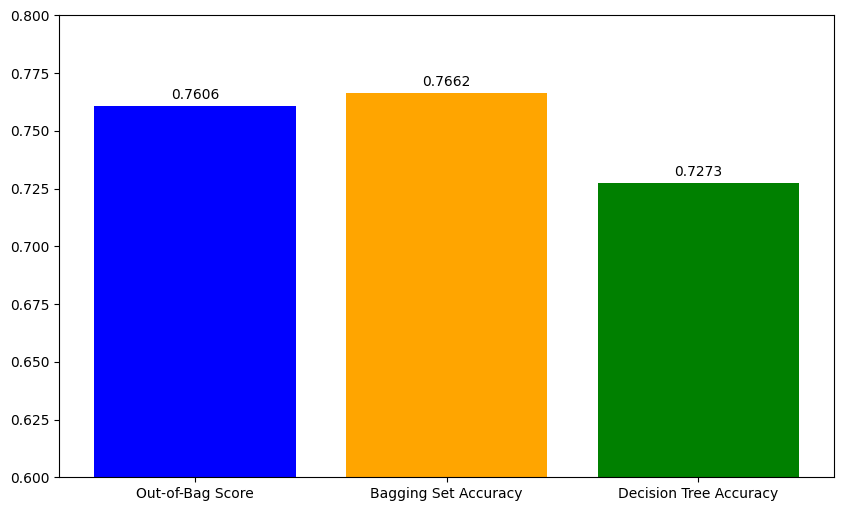

In [9]:
bagging = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('bagging', BaggingClassifier(
    estimator=DecisionTreeClassifier(random_state=42),
    n_estimators=300, bootstrap=True, oob_score=True,
    n_jobs=-1, random_state=42))
    ])

bagging.fit(X_train, y_train)

oob_score = bagging.named_steps['bagging'].oob_score_
print(f'Out-of-Bag Score: {oob_score:.4f}')

accuracy = accuracy_score(y_test, bagging.predict(X_test))
print(f'Accuracy on Test Set: {accuracy:.4f}')

fig, ax = plt.subplots(figsize=(10, 6))
Labels = ['Out-of-Bag Score', 'Bagging Set Accuracy', 'Decision Tree Accuracy']
values = [oob_score, accuracy, models['DecisionTree']['Accuracy']]
bars = ax.bar(Labels, values, color=['blue', 'orange', 'green'])
ax.bar_label(bars, [f'{v:.4f}' for v in values], padding=3)
ax.set_ylim(0.6, 0.8)

## Training a Random Forrest Classifier

In this code cell, I created a Random Forrest model using the preprocessor I made before again. I created it with the out-of-bag evaluation enabled aswell. I then again displayed the OOB score and accuracy score to see they were about the same. Then I took the feature importance values based on mean impurity decrease and put them into a horizontal bar graph to see which features play the largest role in decreasing impurity.

Random Forest Out-of-Bag Score: 0.7524
Random Forest Accuracy on Test Set: 0.7597



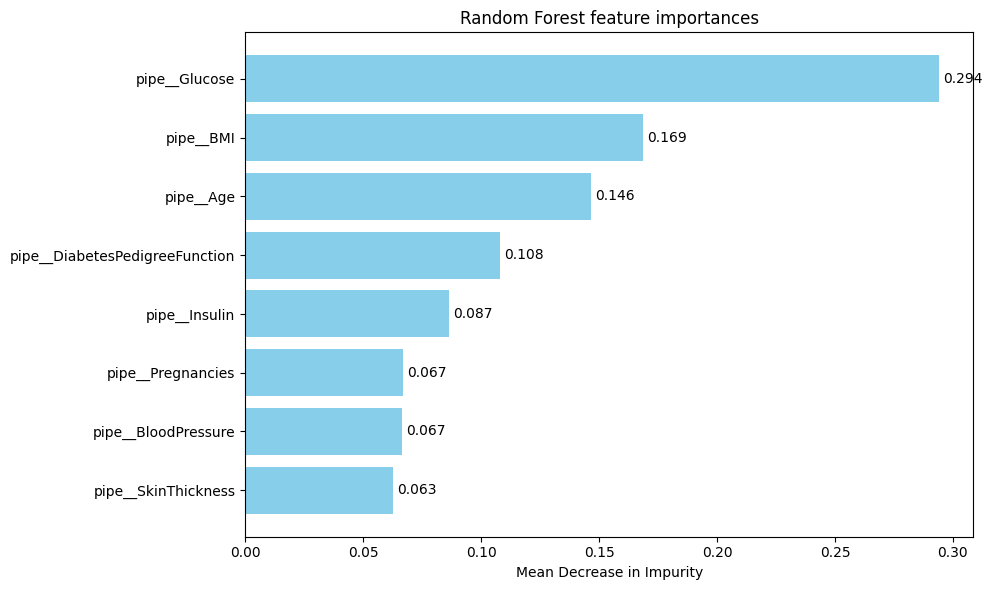

In [10]:
rf = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('clf', RandomForestClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=3,
        oob_score=True, n_jobs=-1, random_state=42))
])
rf.fit(X_train, y_train)

rf_pred = rf.predict(X_test)
rf_oob_score = rf.named_steps['clf'].oob_score_
rf_accuracy = accuracy_score(y_test, rf_pred)

print(f'Random Forest Out-of-Bag Score: {rf_oob_score:.4f}')
print(f'Random Forest Accuracy on Test Set: {rf_accuracy:.4f}\n')

importances = pd.Series(rf.named_steps['clf'].feature_importances_,
                        index=rf.named_steps['preprocessor'].get_feature_names_out()).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(importances.index, importances.values, color='skyblue')
ax.bar_label(bars, labels=[f"{v:.3f}" for v in importances.values], padding=3)
ax.set_xlabel("Mean Decrease in Impurity")
ax.set_title("Random Forest feature importances")
plt.tight_layout()
plt.show()

## AdaBoost with Decision Stumps

In this cell I created Ada Boost Classifiers with learning values of both 1.0 and 0.1 and max depth of 1 so the AdaBoost uses decision stumps. I then access the accuracy scores of both slow and fast models' training and test sets. I inevetably added this data into a bar graph to show that the learning rate of 1.0 was the most accurate.

AdaBoost lr=1.0: train acc = 0.8143 | test acc = 0.7468 | gap = +0.0676
AdaBoost lr=0.1: train acc = 0.7834 | test acc = 0.7662 | gap = +0.0172
Best test accuracy over rounds (lr=1.0): 0.7857 at round 30
Best test accuracy over rounds (lr=0.1): 0.7792 at round 27
              precision    recall  f1-score   support

Non-diabetic       0.81      0.79      0.80        99
    Diabetic       0.64      0.67      0.65        55

    accuracy                           0.75       154
   macro avg       0.73      0.73      0.73       154
weighted avg       0.75      0.75      0.75       154



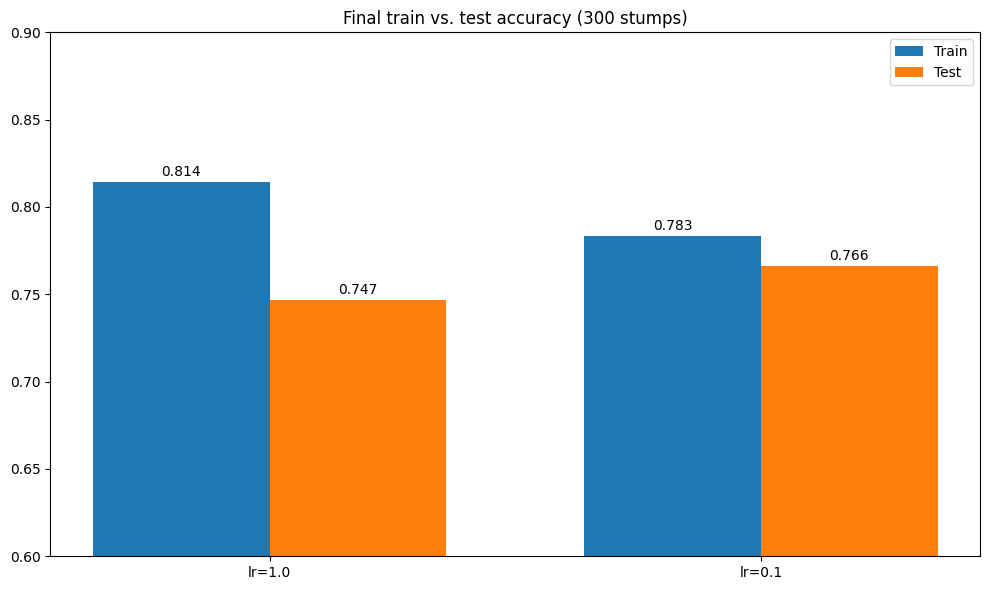

In [11]:
from sklearn.ensemble import AdaBoostClassifier

ada = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('ada', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        n_estimators=300, learning_rate=1.0, random_state=42))
]).fit(X_train, y_train)

ada_slow = Pipeline([
    ('preprocessor', clone(preprocessor)),
    ('ada', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, random_state=42),
        n_estimators=300, learning_rate=0.1, random_state=42))
]).fit(X_train, y_train)

def curves(pipe):
    prep, model = pipe.named_steps["preprocessor"], pipe.named_steps["ada"]
    Xtr, Xte = prep.transform(X_train), prep.transform(X_test)
    return (list(model.staged_score(Xtr, y_train)), list(model.staged_score(Xte, y_test)))

tr1, te1 = curves(ada)
tr2, te2 = curves(ada_slow)

final = {
    "lr=1.0":  (tr1[-1], te1[-1]),
    "lr=0.1":  (tr2[-1], te2[-1]),
}
for k, (a, b) in final.items():
    print(f"AdaBoost {k}: train acc = {a:.4f} | test acc = {b:.4f} | gap = {a-b:+.4f}")
print(f"Best test accuracy over rounds (lr=1.0): {max(te1):.4f} at round {int(np.argmax(te1))+1}")
print(f"Best test accuracy over rounds (lr=0.1): {max(te2):.4f} at round {int(np.argmax(te2))+1}")
print(classification_report(y_test, ada.predict(X_test), target_names=["Non-diabetic", "Diabetic"]))

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(2)
w = 0.36
tr_vals = [final["lr=1.0"][0], final["lr=0.1"][0]]
te_vals = [final["lr=1.0"][1], final["lr=0.1"][1]]
b1 = ax.bar(x - w/2, tr_vals, w, label="Train")
b2 = ax.bar(x + w/2, te_vals, w, label="Test")
ax.bar_label(b1, labels=[f"{v:.3f}" for v in tr_vals], padding=2)
ax.bar_label(b2, labels=[f"{v:.3f}" for v in te_vals], padding=2)
ax.set_xticks(x, ["lr=1.0", "lr=0.1"])
ax.set_ylim(0.6, 0.9)
ax.set_title("Final train vs. test accuracy (300 stumps)")
ax.legend()
plt.tight_layout()
plt.show()